Suhas Gullapelli - Fraud Detection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [2]:
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
# Load the dataset
df = pd.read_csv('AIML Dataset.csv')
# Display the first few rows of the dataset 
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [4]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [5]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [6]:
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [7]:
print(df.shape)
print(df.shape[0])
df.shape[1]

(6362620, 11)
6362620


11

In [8]:
round(df["isFraud"].value_counts()[1]/df.shape[0] * 100, 2)

np.float64(0.13)

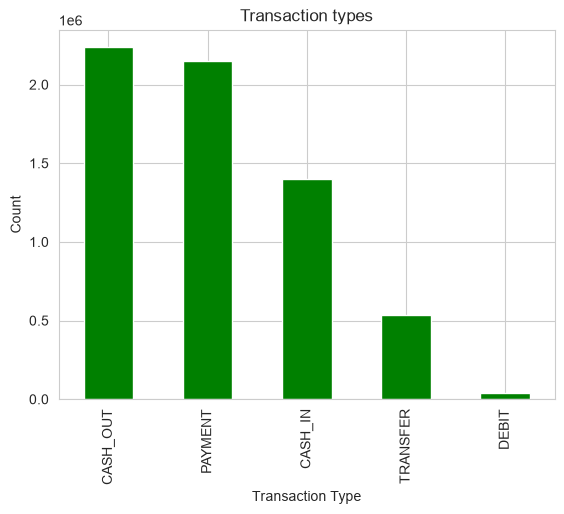

In [9]:
df["type"].value_counts().plot(kind='bar', title='Transaction types', color = "green")
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.show()

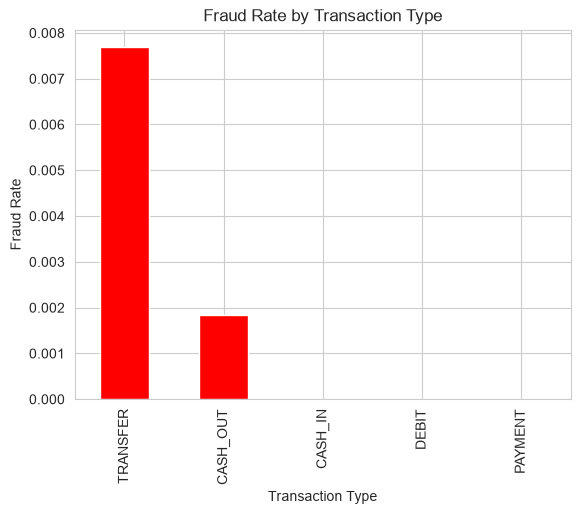

In [10]:
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind='bar', title='Fraud Rate by Transaction Type', color = "red")
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Rate')
plt.show()

In [11]:
df["amount"].describe().astype(int)

count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

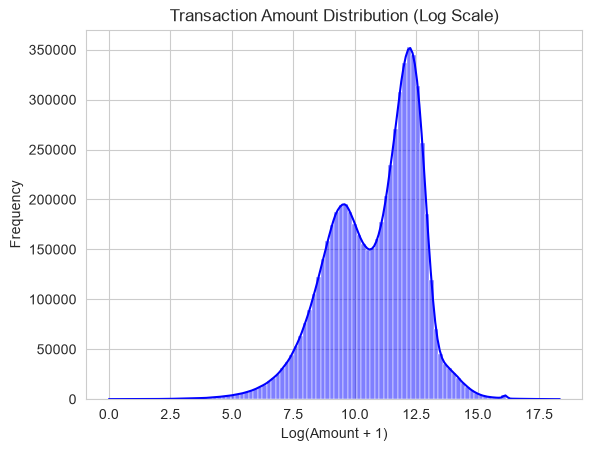

In [12]:
sns.histplot(np.log1p(df['amount']), bins = 100, kde = True, color = "blue")
plt.title('Transaction Amount Distribution (Log Scale)')
plt.xlabel('Log(Amount + 1)')
plt.ylabel('Frequency')
plt.show()

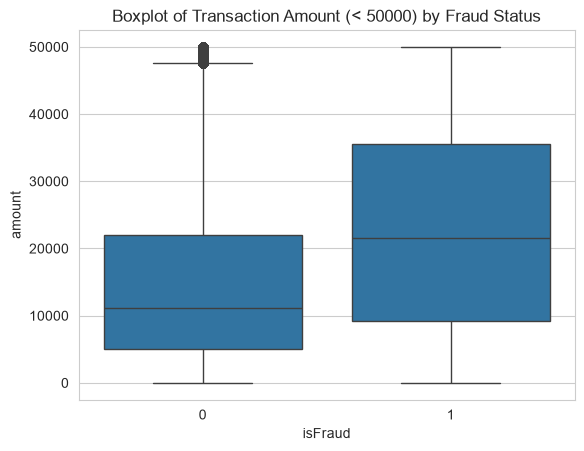

In [13]:
sns.boxplot(data = df[df['amount'] < 50000], x = "isFraud", y="amount")
plt.title('Boxplot of Transaction Amount (< 50000) by Fraud Status')
plt.show()

In [14]:
df["BalanceDiffOG"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["BalanceDiffDest"] = df["oldbalanceDest"] - df["newbalanceDest"]

In [15]:
(df["BalanceDiffOG"] < 0).sum()

np.int64(1399253)

In [16]:
(df['BalanceDiffDest'] < 0).sum()

np.int64(2806464)

In [17]:
df.head(2)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,BalanceDiffOG,BalanceDiffDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0


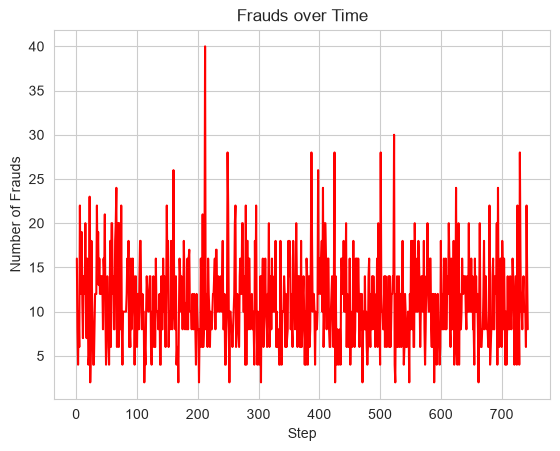

In [18]:
frauds_per_step = df[df['isFraud'] == 1]['step'].value_counts().sort_index()
plt.plot(frauds_per_step.index, frauds_per_step.values, label ='Fraud per step', color='red')
plt.title('Frauds over Time')
plt.xlabel('Step')
plt.ylabel('Number of Frauds')
plt.grid(True)
plt.show()

In [19]:
#df.drop(columns = 'step', inplace = True)
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,BalanceDiffOG,BalanceDiffDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,21182.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [20]:
top_senders = df['nameOrig'].value_counts().head(10)
top_senders

nameOrig
C2098525306    3
C400299098     3
C1999539787    3
C1065307291    3
C545315117     3
C1976208114    3
C1784010646    3
C1530544995    3
C1902386530    3
C1677795071    3
Name: count, dtype: int64

In [21]:
top_recievers = df['nameDest'].value_counts().head(10)
top_recievers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [22]:
fraud_users = df[df['isFraud'] == 1]['nameOrig'].value_counts().head(10)
fraud_users

nameOrig
C1305486145    1
C840083671     1
C1420196421    1
C2101527076    1
C137533655     1
C1118430673    1
C749981943     1
C1334405552    1
C467632528     1
C1364127192    1
Name: count, dtype: int64

## Preparing the data for modeling

In [23]:
# Which transaction types actually contain fraud?
df[df['isFraud'] == 1]['type'].value_counts()

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

Fraud only shows up in `TRANSFER` and `CASH_OUT` transactions, so the model only needs to look at those two types. Every other type is treated as not fraud.

In [24]:
df_model = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()

# Account IDs are unique per customer, so they don't help predict new transactions.
# isFlaggedFraud is the old rule-based flag (only 16 hits), so it is dropped too.
df_model.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'], inplace=True)

# 1 = TRANSFER, 0 = CASH_OUT
df_model['type'] = (df_model['type'] == 'TRANSFER').astype(int)

# Each step is one hour, so step % 24 gives the hour of the day
df_model['hour'] = df_model['step'] % 24
df_model.drop(columns='step', inplace=True)

# Balance errors: how far the recorded balances are from what the amount says they should be
df_model['errorBalanceOrig'] = df_model['newbalanceOrig'] + df_model['amount'] - df_model['oldbalanceOrg']
df_model['errorBalanceDest'] = df_model['oldbalanceDest'] + df_model['amount'] - df_model['newbalanceDest']

print(df_model.shape)
print(round(df_model['isFraud'].mean() * 100, 2), '% fraud')
df_model.head()

(2770409, 12)
0.3 % fraud


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,BalanceDiffOG,BalanceDiffDest,hour,errorBalanceOrig,errorBalanceDest
2,1,181.00,181.0,0.0,0.0,0.00,1,181.0,0.00,1,0.00,181.0
3,0,181.00,181.0,0.0,21182.0,0.00,1,181.0,21182.00,1,0.00,21363.0
15,0,229133.94,15325.0,0.0,5083.0,51513.44,0,15325.0,-46430.44,1,213808.94,182703.5
19,1,215310.30,705.0,0.0,22425.0,0.00,0,705.0,22425.00,1,214605.30,237735.3
24,1,311685.89,10835.0,0.0,6267.0,2719172.89,0,10835.0,-2712905.89,1,300850.89,-2401220.0


In [25]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns='isFraud')
y = df_model['isFraud']

# stratify keeps the same (tiny) fraud rate in both splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.sum(), 'frauds in train,', y_test.sum(), 'frauds in test')

(2216327, 11) (554082, 11)
6570 frauds in train, 1643 frauds in test


## Training models

Fraud is under 0.3% of these rows, so accuracy is misleading: a model that always says "not fraud" is over 99.7% accurate. The models are compared on **precision** (of the transactions flagged, how many are fraud), **recall** (of the frauds, how many were caught), and **PR-AUC** (average precision across all thresholds).

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             average_precision_score, roc_auc_score, PrecisionRecallDisplay)

def evaluate(model, name):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(name)
    print(classification_report(y_test, pred, digits=4))
    print('ROC-AUC:', round(roc_auc_score(y_test, proba), 4))
    print('PR-AUC :', round(average_precision_score(y_test, proba), 4))
    return proba

In [27]:
# Baseline: logistic regression, with class_weight='balanced' to make up for how rare fraud is
log_reg = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))
log_reg.fit(X_train, y_train)
proba_lr = evaluate(log_reg, 'Logistic Regression')

Logistic Regression


              precision    recall  f1-score   support

           0     0.9997    0.9412    0.9696    552439
           1     0.0436    0.8996    0.0831      1643

    accuracy                         0.9411    554082
   macro avg     0.5216    0.9204    0.5263    554082
weighted avg     0.9968    0.9411    0.9670    554082



ROC-AUC: 0.9782


PR-AUC : 0.575


In [28]:
# Gradient boosting handles skewed amounts and balance features without scaling
hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42)
hgb.fit(X_train, y_train)
proba_hgb = evaluate(hgb, 'Histogram Gradient Boosting')

Histogram Gradient Boosting


              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    552439
           1     0.9927    0.9927    0.9927      1643

    accuracy                         1.0000    554082
   macro avg     0.9963    0.9963    0.9963    554082
weighted avg     1.0000    1.0000    1.0000    554082

ROC-AUC: 0.9959


PR-AUC : 0.986


## Comparing the models

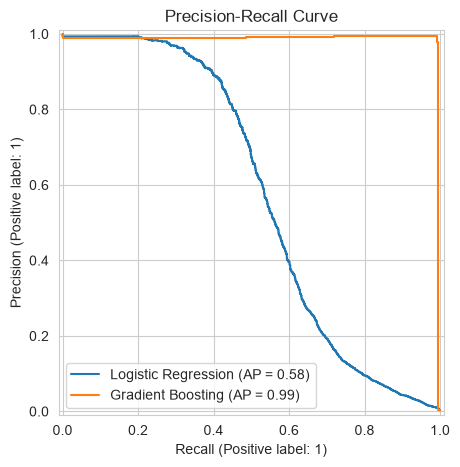

In [29]:
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, name='Logistic Regression', ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_hgb, name='Gradient Boosting', ax=ax)
plt.title('Precision-Recall Curve')
plt.show()

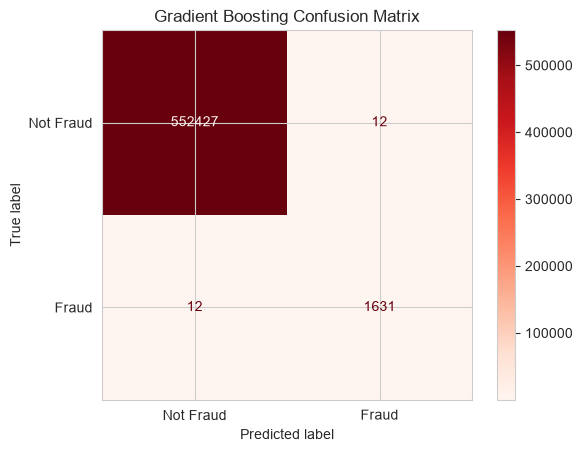

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test, (proba_hgb >= 0.5).astype(int),
                                        display_labels=['Not Fraud', 'Fraud'], cmap='Reds')
plt.title('Gradient Boosting Confusion Matrix')
plt.show()

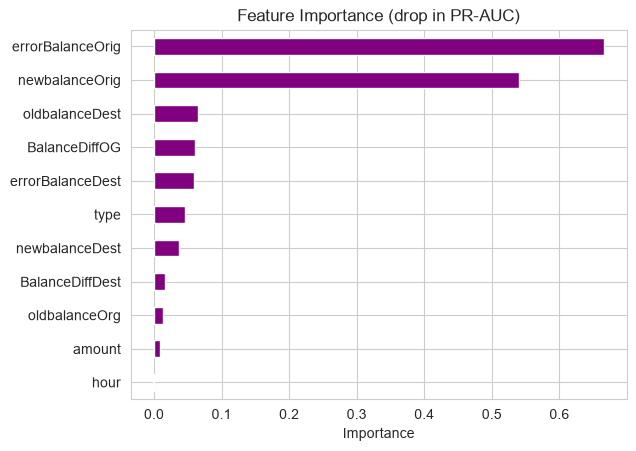

In [31]:
from sklearn.inspection import permutation_importance

# Permutation importance on a sample of the test set (the full set is slow)
sample = X_test.sample(100_000, random_state=42)
result = permutation_importance(hgb, sample, y_test.loc[sample.index], scoring='average_precision',
                                n_repeats=3, random_state=42)
importance = pd.Series(result.importances_mean, index=X.columns).sort_values()
importance.plot(kind='barh', title='Feature Importance (drop in PR-AUC)', color='purple')
plt.xlabel('Importance')
plt.show()

## Saving the model

In [32]:
import joblib

joblib.dump({'model': hgb, 'features': list(X.columns)}, 'fraud_model.joblib')

['fraud_model.joblib']

In [33]:
# Load the saved model and score one new transaction
saved = joblib.load('fraud_model.joblib')

def predict_fraud(type, amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, step):
    if type not in ('TRANSFER', 'CASH_OUT'):
        return 0.0  # no fraud occurs in other transaction types
    row = pd.DataFrame([{
        'type': int(type == 'TRANSFER'),
        'amount': amount,
        'oldbalanceOrg': oldbalanceOrg,
        'newbalanceOrig': newbalanceOrig,
        'oldbalanceDest': oldbalanceDest,
        'newbalanceDest': newbalanceDest,
        'BalanceDiffOG': oldbalanceOrg - newbalanceOrig,
        'BalanceDiffDest': oldbalanceDest - newbalanceDest,
        'hour': step % 24,
        'errorBalanceOrig': newbalanceOrig + amount - oldbalanceOrg,
        'errorBalanceDest': oldbalanceDest + amount - newbalanceDest,
    }])[saved['features']]
    return saved['model'].predict_proba(row)[0, 1]

# A transfer that empties the sender's account into a destination whose balance never changes
print('Fraud probability:', round(predict_fraud('TRANSFER', 181.0, 181.0, 0.0, 0.0, 0.0, step=1), 4))
# An ordinary cash-out
print('Fraud probability:', round(predict_fraud('CASH_OUT', 5000.0, 20000.0, 15000.0, 10000.0, 15000.0, step=10), 4))

Fraud probability: 1.0
Fraud probability: 0.001
